# A1

In [18]:
weight_decay = 0.01
max_epoch = 100
batch_size = 128
patience = 5
initial_lr = 0.001

In [19]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [20]:
import common_utils
import pandas as pd

common_utils.set_seed()
df = pd.read_csv(r"C:\Users\kyeyo\OneDrive\Desktop\SC4001\Individual Assignment\files_PartA\files_PartA\audio_gtzan.csv")
display(df.head())

,filename,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
0,blues.00000.0.wav,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,3714.560359,...,-2.853603,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767
1,blues.00000.1.wav,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,3869.682242,...,4.074709,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081
2,blues.00000.2.wav,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,3997.639160,...,4.806280,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122
3,blues.00000.3.wav,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,3568.300218,...,-1.359111,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678
4,blues.00000.4.wav,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,3469.992864,...,2.092937,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694


In [21]:
test_size = int(len(df)/4)
train_size = len(df) - test_size

# Add class column
df['label'] = 0  # default to 0
df.loc[df['filename'].str.startswith('metal'), 'label'] = 1

df_train_unscaled, y_train, df_test_unscaled, y_test = common_utils.split_dataset(df, ["filename", "label"], test_size, 0)

nd_train, nd_test = common_utils.preprocess_dataset(df_train_unscaled, df_test_unscaled)

from torch.utils.data import DataLoader
# may not use the conversion in AudioDataset, must convert to tensor manually due to audiodataset handling tensors and dataframes but not numpy arrays given by other methods in common utils
train_load = DataLoader(common_utils.AudioDataset(nd_train,
    torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32))
    , batch_size = batch_size)
test_load = DataLoader(common_utils.AudioDataset(nd_test,
    torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32))
    , batch_size = batch_size)


In [22]:
y_train

array([1, 0, 1, ..., 1, 0, 0], dtype=int64)

In [23]:
import torch
import torch.nn as nn

model = common_utils.MLP()
loss_fn = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), weight_decay=weight_decay, lr = initial_lr)
early_stopper = common_utils.EarlyStopper(patience = 5)

In [24]:
def train_loop(dataloader, model, loss_fn, optimizer):
    train_loss= 0
    for _batch, (X, Y) in enumerate(dataloader):
        pred = model(X)
        loss = loss_fn(pred, Y)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    return train_loss

def test_loop(dataloader, model, loss_fn):
    test_loss = 0
    with torch.no_grad():
        for X, y in dataloader:
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
    return test_loss

In [25]:
train_losses = []
test_losses = []
epochs = []

for epoch in range(max_epoch):
    train_loss = train_loop(train_load, model, loss_fn, optimizer)
    test_loss = test_loop(test_load, model, loss_fn)

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    epochs.append(epoch)

    if early_stopper.early_stop(test_loss):
        break

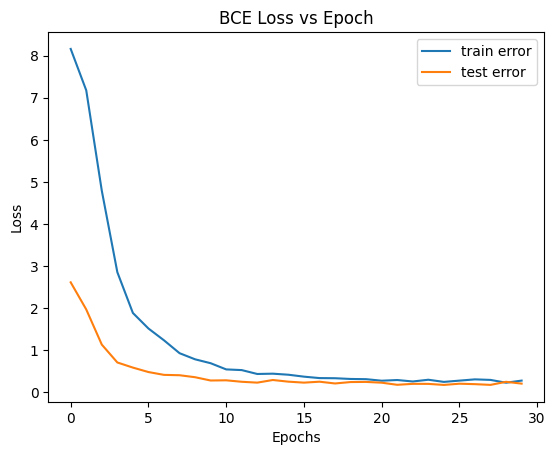

In [26]:
import matplotlib.pyplot as plt 
import numpy as np

plt.plot(epochs, train_losses, label= "train error")
plt.plot(epochs, test_losses, label= "test error")
plt.title("BCE Loss vs Epoch")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

In [27]:
import shap
features = common_utils.extract_features(r"C:\Users\kyeyo\OneDrive\Desktop\SC4001\Individual Assignment\files_PartA\files_PartA\audio_test.wav")
features.drop(labels = ["filename"], axis=1, inplace=True)
# display(features)
features = torch.tensor(features.to_numpy().astype(np.float32), dtype = torch.float)

background_data = 0
for X_batch, Y_batch in train_load:
    background_data = X_batch  
    break  # Take only the first batch

explainer = shap.DeepExplainer(model, background_data)
shap_values = explainer(features)
shap_array = shap_values.values  

# Remove singleton axes
shap_array = np.squeeze(shap_array)   # → shape: (n_features,)

# Mean absolute shap value per feature
feature_importance = np.abs(shap_array)  # absolute SHAP values

# Get top 5 indices
top5_indices = np.argsort(feature_importance)[-5:][::-1]
print("Top 5 Feature Indices:", top5_indices)

print("Top 5 SHAP Values:", feature_importance[top5_indices])

# Map to feature names
feature_names = df.columns[1:]  # ensure these match the 57 features
top5_names = [feature_names[i] for i in top5_indices]
print("Top 5 influential features:", top5_names)

Top 5 Feature Indices: [9 7 5 8 4]
Top 5 SHAP Values: [0.40476352 0.08182067 0.05528307 0.00801922 0.00435503]
Top 5 influential features: ['rolloff_var', 'spectral_bandwidth_var', 'spectral_centroid_var', 'rolloff_mean', 'spectral_centroid_mean']


# Q2

In [110]:
no_folds = 5
lr_list = [1e-4, 5e-4, 1e-3, 5e-3, 1e-2]
batch_size = 128

In [205]:
from sklearn import preprocessing

label_encoder = preprocessing.LabelEncoder()
standard_scaler = preprocessing.StandardScaler()

df_cpy = df.copy()
df_cpy = df.sample(frac=1).reset_index(drop=True)
df_cpy['label'] = label_encoder.fit_transform(df_cpy['label'])
nd_X = df_cpy.drop(["filename", "label"], axis = 1).to_numpy()
nd_Y = df_cpy["label"].to_numpy().reshape(-1, 1)
nd_X = standard_scaler.fit_transform(nd_X)

dataloader_A2 = DataLoader(common_utils.AudioDataset(nd_X,
    torch.tensor(nd_Y.reshape(-1, 1), dtype=torch.float32))
    , batch_size = 128)

In [209]:
from sklearn.metrics import roc_auc_score
import time

def create_folds(X, Y, no_folds):
    X_folds = np.array_split(X, no_folds)
    Y_folds = np.array_split(Y, no_folds)
    return X_folds, Y_folds

def get_train_test_split(X_folds, Y_folds, fold, no_folds):
    x_test, y_test = X_folds[fold].detach().numpy(), Y_folds[fold].detach().numpy()
    x_train = np.concatenate([X_folds[i] for i in range(no_folds) if i != fold], axis=0)
    y_train = np.concatenate([Y_folds[i] for i in range(no_folds) if i != fold], axis=0)
    return x_train, y_train, x_test, y_test

def train_one_fold(x_train, y_train, x_test, y_test, lr, max_epoch):
    model = common_utils.MLP()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.BCELoss()
    early_stopper = common_utils.EarlyStopper()

    x_train_tensor = torch.tensor(x_train, dtype=torch.float)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float)
    x_test_tensor = torch.tensor(x_test, dtype=torch.float)
    y_test_tensor = torch.tensor(y_test, dtype=torch.float)

    epoch = 0
    train_loss = 0.0
    test_loss = 0.0
    pred_train = torch.tensor([])
    pred_test = torch.tensor([])

    for epoch in range(max_epoch):
        model.train()
        optimizer.zero_grad()
        pred_train = model(x_train_tensor)
        train_loss = loss_fn(pred_train, y_train_tensor).item()
        loss_fn(pred_train, y_train_tensor).backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            pred_test = model(x_test_tensor)
            test_loss = loss_fn(pred_test, y_test_tensor).item()

        if early_stopper.early_stop(test_loss):
            break

    return epoch, train_loss, test_loss, pred_train.detach().numpy().ravel(), pred_test.detach().numpy().ravel()

def record_performance(performance, fold, lr_idx, epoch, train_loss, test_loss, pred_train_prob, pred_test_prob, y_train, y_test):
    pred_train_np = (pred_train_prob >= 0.5).astype(int)
    pred_test_np = (pred_test_prob >= 0.5).astype(int)

    # Train metrics
    performance[fold, lr_idx, 0, 0] = train_loss
    performance[fold, lr_idx, 0, 1] = safe_auc(y_train.ravel(), pred_train_prob)
    performance[fold, lr_idx, 0, 3] = epoch
    performance[fold, lr_idx, 0, 4] = np.mean(pred_train_np == y_train.ravel())

    # Test metrics
    performance[fold, lr_idx, 1, 0] = test_loss
    performance[fold, lr_idx, 1, 1] = safe_auc(y_test.ravel(), pred_test_prob)
    performance[fold, lr_idx, 1, 3] = epoch
    performance[fold, lr_idx, 1, 4] = np.mean(pred_test_np == y_test.ravel())

def safe_auc(y_true, y_prob):
    try:
        return roc_auc_score(y_true, y_prob)
    except:
        return np.nan

def initialize_fold_accumulators(no_folds):
    """Initialize per-fold data accumulators."""
    return {
        fold: {"x_train": [], "y_train": [], "pred_train": [],
               "x_test": [], "y_test": [], "pred_test": []}
        for fold in range(no_folds)
    }


def process_learning_rate(lr_idx, lr, fold_accum, performance):
    """Run training across all data batches for one learning rate."""
    for X_batch, Y_batch in dataloader_A2:
        X_folds, Y_folds = create_folds(X_batch, Y_batch, no_folds)
        for fold in range(no_folds):
            process_fold(fold, X_folds, Y_folds, lr, lr_idx, fold_accum, performance)


def process_fold(fold, X_folds, Y_folds, lr, lr_idx, fold_accum, performance):
    """Train and record results for one fold."""
    x_train, y_train, x_test, y_test = get_train_test_split(X_folds, Y_folds, fold, no_folds)

    epoch, train_loss, test_loss, pred_train_prob, pred_test_prob = train_one_fold(
        x_train, y_train, x_test, y_test, lr, max_epoch
    )

    record_performance(
        performance, fold, lr_idx, epoch,
        train_loss, test_loss,
        pred_train_prob, pred_test_prob,
        y_train, y_test
    )

    update_fold_accumulator(fold_accum[fold], x_train, y_train, pred_train_prob,
                            x_test, y_test, pred_test_prob)


def update_fold_accumulator(fold_data, x_train, y_train, pred_train,
                            x_test, y_test, pred_test):
    """Append data from one batch to the fold accumulators."""
    fold_data["x_train"].append(x_train)
    fold_data["y_train"].append(y_train.reshape(-1))
    fold_data["pred_train"].append(pred_train.reshape(-1))
    fold_data["x_test"].append(x_test)
    fold_data["y_test"].append(y_test.reshape(-1))
    fold_data["pred_test"].append(pred_test.reshape(-1))


def finalize_fold_data(fold_accum, X_Y, performance, lr_idx, elapsed_time):
    """Combine accumulated fold data into numpy arrays and record timing."""
    for fold in range(no_folds):
        X_Y[fold, lr_idx, 0, 0] = np.vstack(fold_accum[fold]["x_train"])
        X_Y[fold, lr_idx, 0, 1] = np.hstack(fold_accum[fold]["y_train"])
        X_Y[fold, lr_idx, 0, 2] = np.hstack(fold_accum[fold]["pred_train"])
        X_Y[fold, lr_idx, 1, 0] = np.vstack(fold_accum[fold]["x_test"])
        X_Y[fold, lr_idx, 1, 1] = np.hstack(fold_accum[fold]["y_test"])
        X_Y[fold, lr_idx, 1, 2] = np.hstack(fold_accum[fold]["pred_test"])

        # Record training duration
        for phase in range(2):  # train/test
            performance[fold, lr_idx, phase, 2] = elapsed_time


def train(X, Y, lr_list):
    performance = np.zeros((5, len(lr_list), 2, 5), dtype=np.float64)
    X_Y = np.zeros([5, len(lr_list), 2, 3], dtype=object)

    for lr_idx, lr in enumerate(lr_list):
        t_start = time.time()

        fold_accum = initialize_fold_accumulators(no_folds)
        process_learning_rate(lr_idx, lr, fold_accum, performance)

        t_end = time.time()
        finalize_fold_data(fold_accum, X_Y, performance, lr_idx, t_end - t_start)

    return performance, X_Y

In [217]:
performance, X_Y = train(nd_X, nd_Y, lr_list)

# use these dicts for final submission since some students want these dicts?? not in the assignment pdf/slides though
# # initialize dicts
# X_train_scaled_dict, X_test_scaled_dict, y_train_dict, y_test_dict = {}, {}, {}, {}
# for lr_idx, lr in enumerate(lr_list):
#     X_train_scaled_dict[lr] = [X_Y[f, lr_idx, 0, 0] for f in range(no_folds)]
#     X_test_scaled_dict[lr]   = [X_Y[f, lr_idx, 1, 0] for f in range(no_folds)]
#     y_train_dict[lr]        = [X_Y[f, lr_idx, 0, 1].reshape(-1) for f in range(no_folds)]
#     y_test_dict[lr]          = [X_Y[f, lr_idx, 1, 1].reshape(-1) for f in range(no_folds)]

performance shape: (5, 5, 2, 5)
lr	mean_acc	mean_auc
0.0001	0.4125	0.5097
0.0005	0.4500	0.4543
0.001	0.5750	0.5763
0.005	0.4750	0.7780
0.01	0.6000	0.8718


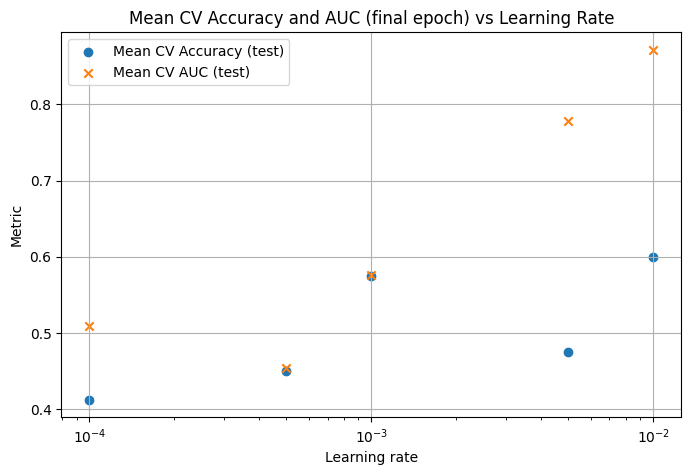

In [218]:
# Aggregate mean CV accuracy and mean CV AUC (final epoch) across folds, then plot vs learning rate
import matplotlib.pyplot as plt
import numpy as np

# indices: LOSS=0, AUC=1, TIME=2, EPOCH=3, ACC=4
LOSS_IDX, AUC_IDX, TIME_IDX, EPOCH_IDX, ACC_IDX = 0, 1, 2, 3, 4

# performance expected shape: (no_folds, len(lr_list), 2, 5)
print('performance shape:', performance.shape)

# take metrics from the test split (index 1)
mean_accs = np.nanmean(performance[:, :, 1, ACC_IDX], axis=0)
mean_aucs = np.nanmean(performance[:, :, 1, AUC_IDX], axis=0)

# Print a small summary table
print('lr\tmean_acc\tmean_auc')
for lr, a, auc in zip(lr_list, mean_accs, mean_aucs):
    print(f"{lr}\t{a:.4f}\t{auc:.4f}")

# Scatter plot
plt.figure(figsize=(8,5))
plt.scatter(lr_list, mean_accs, label='Mean CV Accuracy (test)', marker='o')
plt.scatter(lr_list, mean_aucs, label='Mean CV AUC (test)', marker='x')
plt.xscale('log')
plt.xlabel('Learning rate')
plt.ylabel('Metric')
plt.title('Mean CV Accuracy and AUC (final epoch) vs Learning Rate')
plt.legend()
plt.grid(True)
plt.show()

In [219]:
# Compute mean last-epoch training time vs learning rate and produce confusion matrix for chosen lr
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def compute_mean_metrics(performance, lr_list):
    TIME_IDX, ACC_IDX = 2, 4

    mean_times = np.nanmean(performance[:, :, 0, TIME_IDX], axis=0)
    mean_accs = np.nanmean(performance[:, :, 1, ACC_IDX], axis=0)

    time_table = pd.DataFrame({
        'learning_rate': lr_list,
        'mean_last_epoch_time_s': mean_times,
        'mean_test_acc': mean_accs
    })

    return time_table

def select_optimal_lr(time_table):
    best_idx = np.nanargmax(time_table['mean_test_acc'].values)
    ties = np.where(np.isclose(time_table['mean_test_acc'].values,
                               time_table['mean_test_acc'].values[best_idx]))[0]
    if len(ties) > 1:
        best_idx = ties[np.argmin(time_table['mean_last_epoch_time_s'].values[ties])]
    return best_idx, time_table.loc[best_idx, 'learning_rate']

time_table = compute_mean_metrics(performance, lr_list)
display(time_table)
best_idx, optimal_lr = select_optimal_lr(time_table)
print(f"Selected optimal learning rate: {optimal_lr}")

optim_performance, X_Y = train(nd_X, nd_Y, [optimal_lr])

,learning_rate,mean_last_epoch_time_s,mean_test_acc
0,0.0001,12.856166,0.4125
1,0.0005,15.399739,0.4500
2,0.0010,13.871172,0.5750
3,0.0050,10.159448,0.4750
4,0.0100,9.945997,0.6000


Selected optimal learning rate: 0.01


<function __main__.compute_mean_metrics(performance, lr_list)>

In [224]:
# print(X_Y[0, 0, 0, 1])
# Build true labels and predicted probabilities across folds
Y = np.concatenate([X_Y[fold, 0, 1, 1] for fold in range(no_folds)], axis=0).ravel().astype(int)
pred_probs = np.concatenate([X_Y[fold, 0, 1, 2] for fold in range(no_folds)], axis=0).ravel()
# Threshold probabilities at 0.5 to obtain class predictions
pred = (pred_probs >= 0.5).astype(int)

Y shape: (2000,) pred_probs shape: (2000,) pred shape: (2000,)


Confusion matrix for selected configuration:
[[575 425]
 [504 496]]


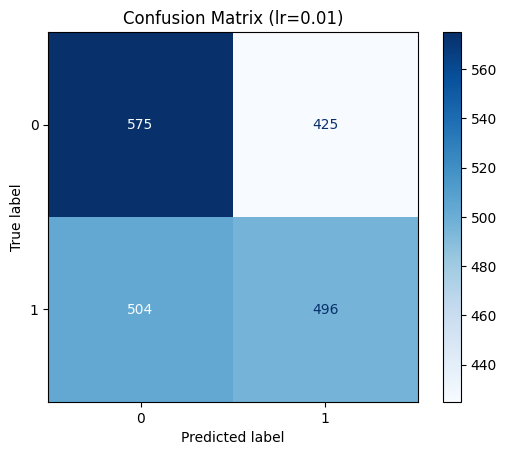


Selection reason:
Selected learning rate 0.01 because it achieved the highest mean test accuracy across folds (mean test acc = 0.6000). When there was a tie in accuracy, the learning rate with lower mean training time was chosen.


In [225]:
cm = confusion_matrix(Y, pred)
print('Confusion matrix for selected configuration:')
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1])
disp.plot(cmap='Blues')
plt.title(f'Confusion Matrix (lr={optimal_lr})')
plt.show()

# Reason for selection
reason = (
    f"Selected learning rate {optimal_lr} because it achieved the highest mean test accuracy "
    f"across folds (mean test acc = {time_table.loc[best_idx, 'mean_test_acc']:.4f}). "
    "When there was a tie in accuracy, the learning rate with lower mean training time was chosen."
)
print('\nSelection reason:')
print(reason)


# A3

Running hidden size 64...
Hidden 64: mean final val acc = 0.5205
Running hidden size 128...
Control: NN unable to learn
(1600, 57)
Anomaly: NN able to learn
(1600, 57)
Hidden 128: mean final val acc = 0.5040
Running hidden size 256...
Hidden 256: mean final val acc = 0.5100


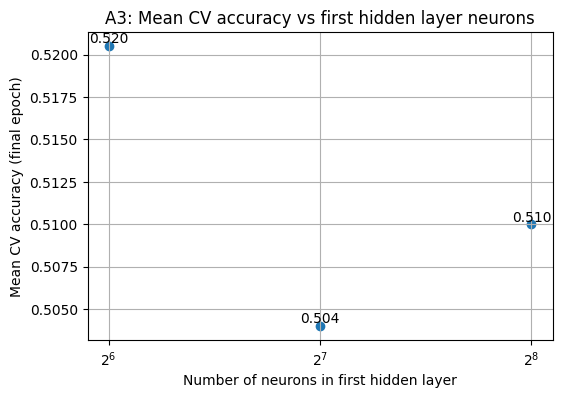

Optimal number of neurons selected: 64


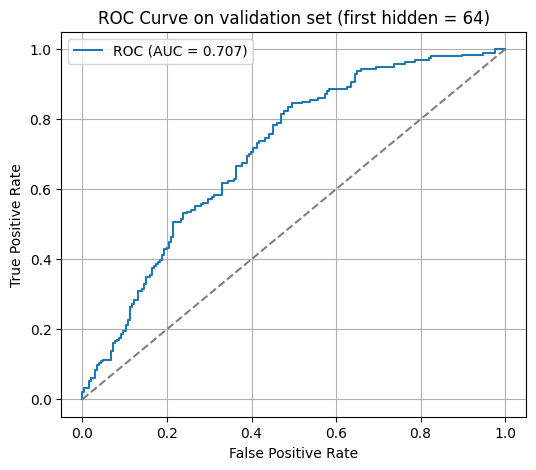

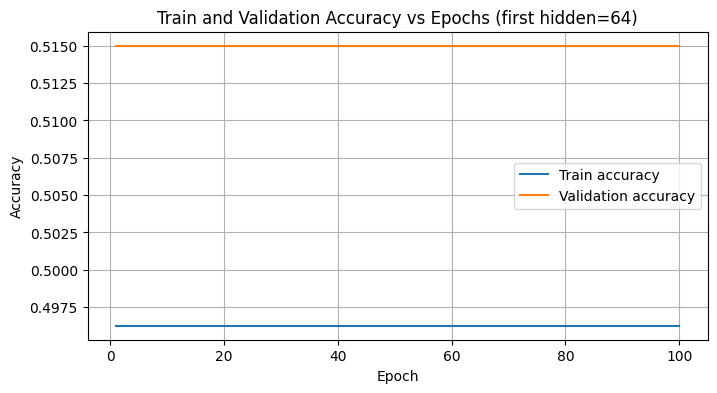

Rationale: selected the number of neurons in the first hidden layer that achieved the highest mean cross-validation accuracy on the final epoch. In case of ties the smallest architecture among tied options was chosen for parsimony.


In [ ]:
# A3: Search optimal number of neurons for first hidden layer among {64,128,256}
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.metrics import roc_curve, auc
import time

# Reuse preprocessed data nd_X, nd_Y from earlier cells (nd_X is scaled features, nd_Y labels)
hidden_options = [64, 128, 256]
no_folds = 5
max_epoch = 100
lr = optimal_lr if 'optimal_lr' in globals() else 1e-2

def train_fold(model, x_train, y_train, x_test, y_test, lr = optimal_lr if 'optimal_lr' in globals() else 1e-2):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.BCELoss()
    early_stopper = common_utils.EarlyStopper()

    x_train_t = torch.tensor(x_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32)
    pred_train = np.array([])
    x_test_t = torch.tensor(x_val, dtype=torch.float32)
    y_test_t = torch.tensor(y_val, dtype=torch.float32)
    pred_test = np.array([])
    epoch = 0

    train_acc_hist = []
    val_acc_hist = []

    ###############################################
    # Debug: initial data stats
    try:
        print('DEBUG: x_train shape, x_val shape ->', x_train.shape, x_val.shape)
        print('DEBUG: y_train distribution ->', np.bincount(y_train.astype(int)))
        print('DEBUG: y_val distribution ->', np.bincount(y_val.astype(int)))
        print('DEBUG: x_train min/mean/max ->', np.nanmin(x_train), np.nanmean(x_train), np.nanmax(x_train))
        print('DEBUG: any NaNs in x_train/x_val? ->', np.isnan(x_train).any(), np.isnan(x_val).any())
    except Exception as e:
        print('DEBUG: error printing initial stats:', e)

    # Debug: model parameter count
    total_params = sum(p.numel() for p in model.parameters())
    print('DEBUG: model total params ->', total_params)
    ###############################################

    for epoch in range(max_epoch):
        model.train()
        optimizer.zero_grad()
        pred = model(x_train_t).flatten()
        loss = loss_fn(pred, y_train_t).mean()
        loss.backward()
        optimizer.step()

        # eval
        model.eval()
        with torch.no_grad():
            pred_train = model(x_train_t).view(-1).detach().numpy()
            pred_test = model(x_test_t).view(-1).detach().numpy()

        train_acc = np.mean((pred_train >= 0.5).astype(int) == y_train.ravel())
        val_acc = np.mean((pred_test >= 0.5).astype(int) == y_test.ravel())

        train_acc_hist.append(train_acc)
        val_acc_hist.append(val_acc)

        ###############################################
        # Debug: record intermediate losses and weight norms occasionally
        if epoch % 10 == 0 or epoch == 0:
            with torch.no_grad():
                # compute loss on train and val for logging
                try:
                    train_loss_dbg = float(loss_fn(torch.tensor(pred_train, dtype=torch.float).view(-1,1), torch.tensor(y_train, dtype=torch.float).view(-1,1)).mean())
                except Exception:
                    train_loss_dbg = float('nan')
                try:
                    val_loss = float(loss_fn(torch.tensor(pred_test, dtype=torch.float).view(-1,1), torch.tensor(y_val, dtype=torch.float).view(-1,1)).mean())
                except Exception:
                    val_loss = float('nan')
                weight_norm = 0.0
                for p in model.parameters():
                    try:
                        weight_norm += float(torch.norm(p).item())
                    except Exception:
                        pass
                print(f'DEBUG epoch {epoch}: train_loss={train_loss_dbg:.6f}, val_loss={val_loss:.6f}, train_acc={train_acc:.4f}, val_acc={val_acc:.4f}, weight_norm={weight_norm:.6f}')
        else:
            try:
                val_loss = float(loss_fn(torch.tensor(pred_test, dtype=torch.float).view(-1,1), torch.tensor(y_val, dtype=torch.float).view(-1,1)).mean())
            except Exception:
                val_loss = float('nan')
        ###############################################

        # Early stopping
        if early_stopper.early_stop(val_loss):
            print(f'DEBUG: Early stopping triggered at epoch {epoch} with val_loss={val_loss:.6f}') ###############################################
            break

    return train_acc_hist, val_acc_hist, pred_test, epoch

# Run 5-fold CV for each hidden option and record mean final-epoch validation accuracy
kf = KFold(n_splits=no_folds, shuffle=True, random_state=0)
mean_final_test_accs = []
all_fold_histories = {}  # store histories for plotting later for chosen model

for h in hidden_options:
    final_accs = []
    fold_histories = []
    print(f'Running hidden size {h}...')
    for train_idx, val_idx in kf.split(nd_X):
        x_train, x_val = nd_X[train_idx], nd_X[val_idx]
        y_train, y_val = nd_Y[train_idx].reshape(-1), nd_Y[val_idx].reshape(-1)
        #########
        if h == 128 and len(fold_histories) ==0:
            print("Control: NN unable to learn")
            df_debug = pd.DataFrame(x_train)
            df_debug.describe()
            print(x_train.shape)

        if h == 128 and len(fold_histories)==2:
            print("Anomaly: NN able to learn")
            df_debug = pd.DataFrame(x_train)
            df_debug.describe()
            print(x_train.shape)
        ##########

        model = common_utils.MLP(input_dim=nd_X.shape[1], hidden_sizes=[h, 128, 64, 32])
        train_hist, test_hist, pred_test, epochs_ran = train_fold(model, x_train, y_train, x_val, y_val, lr=lr)

        final_accs.append(test_hist[-1])
        fold_histories.append((train_hist, test_hist))

    mean_final = np.mean(final_accs)
    mean_final_test_accs.append(mean_final)
    all_fold_histories[h] = fold_histories
    print(f'Hidden {h}: mean final val acc = {mean_final:.4f}')

# Scatter plot of mean CV accuracies vs hidden sizes
plt.figure(figsize=(6,4))
plt.scatter(hidden_options, mean_final_test_accs)
for x,y in zip(hidden_options, mean_final_test_accs):
    plt.text(x, y, f'{y:.3f}', va='bottom', ha='center')
plt.xscale('log', base=2)
plt.xlabel('Number of neurons in first hidden layer')
plt.ylabel('Mean CV accuracy (final epoch)')
plt.title('A3: Mean CV accuracy vs first hidden layer neurons')
plt.grid(True)
plt.show()

# Select optimal number: highest mean_final_test_accs, tie-break by smaller training time not available here so pick smallest h among ties
best_idx = int(np.argmax(mean_final_test_accs))
optimal_h = hidden_options[best_idx]
print(f'Optimal number of neurons selected: {optimal_h}')

# For the optimal model, retrain on full training set and produce ROC on held-out validation set (use last split of KFold as 'validation')
# Here we will retrain using a single train/val split from the last kf iteration stored earlier
train_idx, val_idx = list(kf.split(nd_X))[-1]
x_train_full, x_test_full = nd_X[train_idx], nd_X[val_idx]
y_train_full, y_test_full = nd_Y[train_idx].reshape(-1), nd_Y[val_idx].reshape(-1)
model_opt = common_utils.MLP(input_dim=nd_X.shape[1], hidden_sizes=[optimal_h, 128, 64, 32])
train_hist_opt, val_hist_opt, pred_test_opt, epochs_ran = train_fold(model_opt, x_train_full, y_train_full, x_test_full, y_test_full, lr=lr)

# ROC curve
fpr, tpr, thresholds = roc_curve(y_test_full, pred_test_opt)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'ROC (AUC = {roc_auc:.3f})')
plt.plot([0,1],[0,1],'--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve on validation set (first hidden = {optimal_h})')
plt.legend()
plt.grid(True)
plt.show()

# Plot train and validation accuracies vs epochs for optimal model (use histories)
# We have train_hist_opt and val_hist_opt for the final run; if shorter than max_epoch that's fine
plt.figure(figsize=(8,4))
plt.plot(range(1, len(train_hist_opt)+1), train_hist_opt, label='Train accuracy')
plt.plot(range(1, len(val_hist_opt)+1), val_hist_opt, label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title(f'Train and Validation Accuracy vs Epochs (first hidden={optimal_h})')
plt.legend()
plt.grid(True)
plt.show()

# Print rationale for selection
print('Rationale: selected the number of neurons in the first hidden layer that achieved the highest mean cross-validation accuracy on the final epoch. In case of ties the smallest architecture among tied options was chosen for parsimony.')


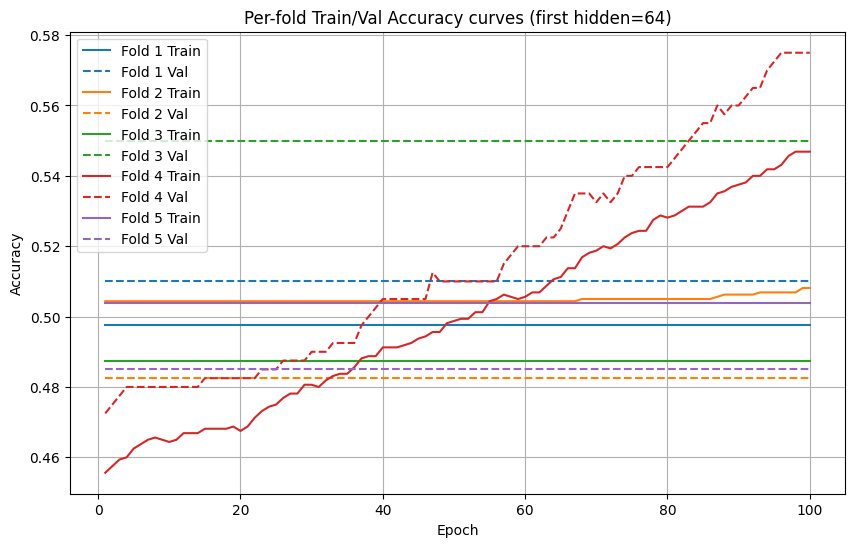

In [248]:
# Optional: show per-fold train/test accuracy curves for the chosen architecture
h = optimal_h
fold_histories = all_fold_histories[h]
plt.figure(figsize=(10,6))
for i, (train_hist, val_hist) in enumerate(fold_histories):
    plt.plot(range(1, len(train_hist)+1), train_hist, label=f'Fold {i+1} Train', color='C'+str(i), linestyle='-')
    plt.plot(range(1, len(val_hist)+1), val_hist, label=f'Fold {i+1} Val', color='C'+str(i), linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title(f'Per-fold Train/Val Accuracy curves (first hidden={h})')
plt.legend()
plt.grid(True)
plt.show()

In [249]:
fold_histories[3]

([0.455625,
  0.4575,
  0.459375,
  0.46,
  0.4625,
  0.46375,
  0.465,
  0.465625,
  0.465,
  0.464375,
  0.465,
  0.466875,
  0.466875,
  0.466875,
  0.468125,
  0.468125,
  0.468125,
  0.468125,
  0.46875,
  0.4675,
  0.46875,
  0.47125,
  0.473125,
  0.474375,
  0.475,
  0.476875,
  0.478125,
  0.478125,
  0.480625,
  0.480625,
  0.48,
  0.481875,
  0.483125,
  0.48375,
  0.48375,
  0.485625,
  0.488125,
  0.48875,
  0.48875,
  0.49125,
  0.49125,
  0.49125,
  0.491875,
  0.4925,
  0.49375,
  0.494375,
  0.495625,
  0.495625,
  0.498125,
  0.49875,
  0.499375,
  0.499375,
  0.50125,
  0.50125,
  0.504375,
  0.505,
  0.50625,
  0.505625,
  0.505,
  0.505625,
  0.506875,
  0.506875,
  0.50875,
  0.510625,
  0.51125,
  0.51375,
  0.51375,
  0.516875,
  0.518125,
  0.51875,
  0.52,
  0.519375,
  0.520625,
  0.5225,
  0.52375,
  0.524375,
  0.524375,
  0.5275,
  0.52875,
  0.528125,
  0.52875,
  0.53,
  0.53125,
  0.53125,
  0.53125,
  0.5325,
  0.535,
  0.535625,
  0.536875,
  0.5375,
